# MANE 4961: Engineering with Machine Learning — Homework 4

**Name:** Soumyanil Sadhu Deep
**RIN:** 662110663

Neural networks for classification (CIFAR-10) and regression (NASA airfoil self-noise). Both models are fully connected networks built with Keras.

In [1]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'

import itertools
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import keras
from keras import layers
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, confusion_matrix, ConfusionMatrixDisplay

SEED = 42
keras.utils.set_random_seed(SEED)
print('Keras', keras.__version__, '| backend:', keras.backend.backend())

Keras 3.15.1 | backend: tensorflow


## Problem 1: Fully connected neural network for CIFAR-10

CIFAR-10 has 60,000 32×32 RGB images in 10 classes (50,000 in the official training set, 10,000 in the official test set).

**Data split.** The 50,000 official training images are split **70% / 30%** into training (35,000) and validation (15,000) sets, stratified by class. The validation set is used for the grid search and for the loss/accuracy curves. The 10,000 official test images are never used for tuning; they are only used at the end as an unbiased check of the tuned network.

In [2]:
(x_full, y_full), (x_test, y_test) = keras.datasets.cifar10.load_data()
y_full, y_test = y_full.ravel(), y_test.ravel()

class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']

x_train, x_val, y_train, y_val = train_test_split(
    x_full, y_full, test_size=0.30, stratify=y_full, random_state=SEED)

print('Training  :', x_train.shape, y_train.shape)
print('Validation:', x_val.shape, y_val.shape)
print('Test      :', x_test.shape, y_test.shape)
print('Train/val fraction: %.2f / %.2f' % (len(x_train) / len(x_full), len(x_val) / len(x_full)))
print('Images per class (train):', np.bincount(y_train))
print('Images per class (val)  :', np.bincount(y_val))

Training  : (35000, 32, 32, 3) (35000,)
Validation: (15000, 32, 32, 3) (15000,)
Test      : (10000, 32, 32, 3) (10000,)
Train/val fraction: 0.70 / 0.30
Images per class (train): [3500 3500 3500 3500 3500 3500 3500 3500 3500 3500]
Images per class (val)  : [1500 1500 1500 1500 1500 1500 1500 1500 1500 1500]


### 1(i) One image from each category

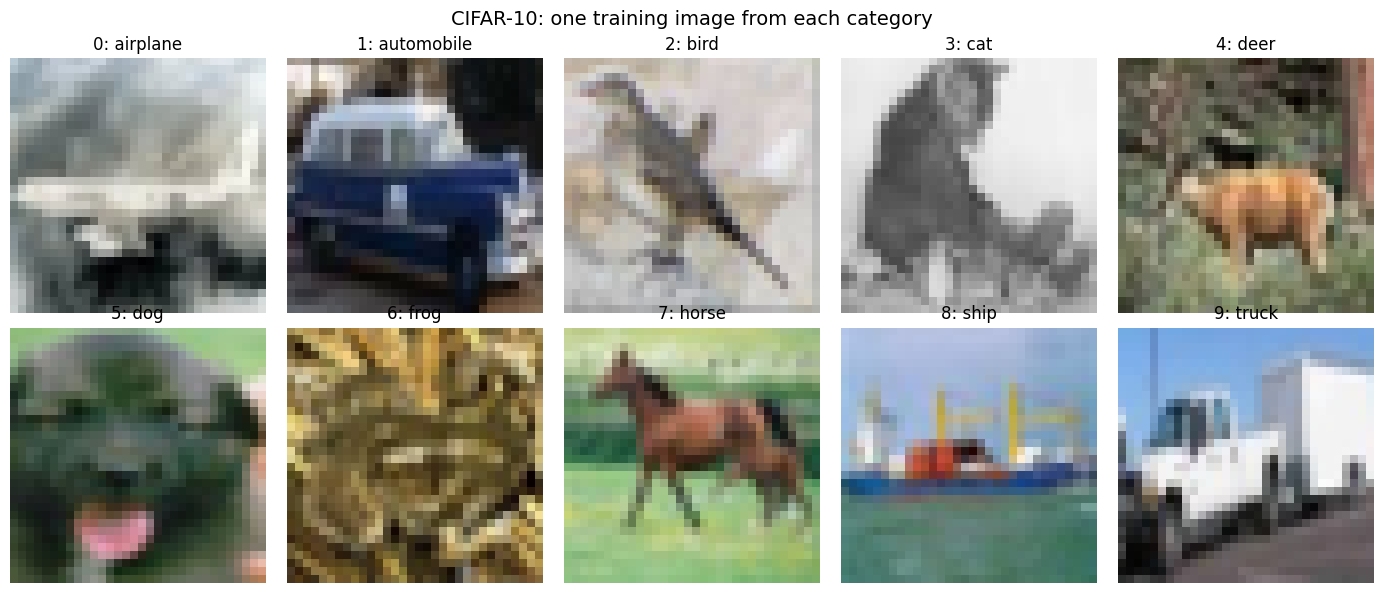

In [3]:
fig, axes = plt.subplots(2, 5, figsize=(14, 6))
for c, ax in enumerate(axes.flat):
    idx = np.where(y_train == c)[0][0]
    ax.imshow(x_train[idx])
    ax.set_title(f'{c}: {class_names[c]}')
    ax.axis('off')
plt.suptitle('CIFAR-10: one training image from each category', fontsize=14)
plt.tight_layout()
plt.show()

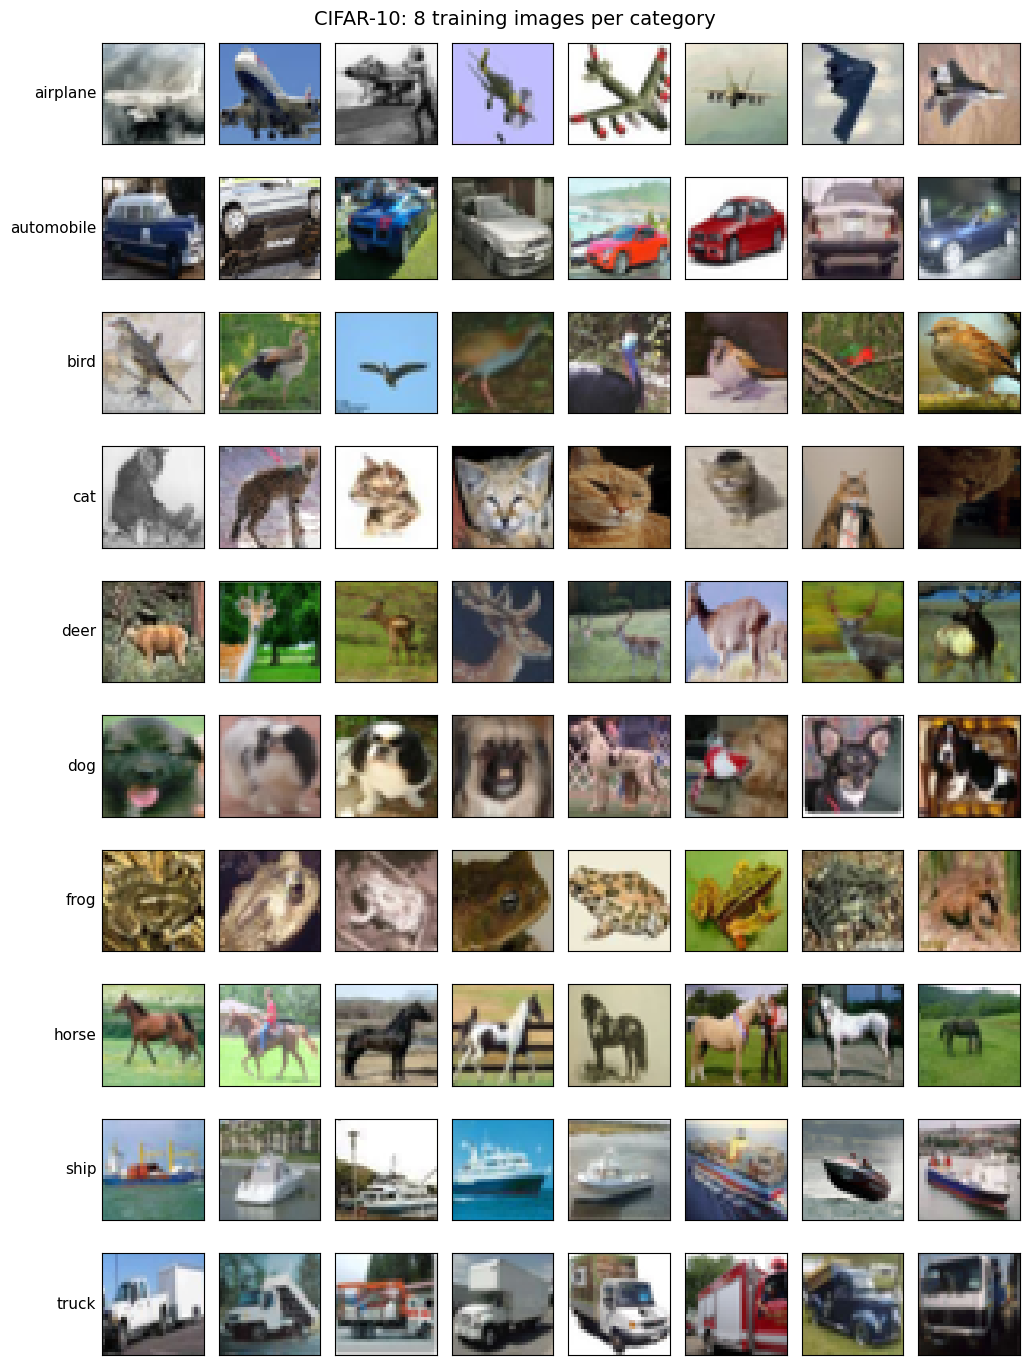

In [4]:
# A few more examples per class to show the variety within each category
n_per_class = 8
fig, axes = plt.subplots(10, n_per_class, figsize=(n_per_class * 1.3, 10 * 1.4))
for c in range(10):
    idx = np.where(y_train == c)[0][:n_per_class]
    for j, i in enumerate(idx):
        ax = axes[c, j]
        ax.imshow(x_train[i])
        ax.set_xticks([]); ax.set_yticks([])
        if j == 0:
            ax.set_ylabel(class_names[c], rotation=0, ha='right', va='center', fontsize=11)
plt.suptitle(f'CIFAR-10: {n_per_class} training images per category', fontsize=14)
plt.tight_layout()
plt.show()

### Preprocessing

A fully connected network takes a vector, so each 32×32×3 image is flattened into a 3072-element vector. Pixels are scaled to [0, 1] and then standardized per color channel using the mean and standard deviation of the **training** set only (so no information from the validation/test sets leaks into training).

In [5]:
def flatten(x):
    return x.reshape(len(x), -1).astype('float32') / 255.0

mean_c = (x_train / 255.0).mean(axis=(0, 1, 2))
std_c = (x_train / 255.0).std(axis=(0, 1, 2))
mean_vec = np.tile(mean_c, 32 * 32).astype('float32')   # channel order repeats every 3 values
std_vec = np.tile(std_c, 32 * 32).astype('float32')

X_train = (flatten(x_train) - mean_vec) / std_vec
X_val = (flatten(x_val) - mean_vec) / std_vec
X_test = (flatten(x_test) - mean_vec) / std_vec

print('Channel means:', mean_c.round(4), ' Channel stds:', std_c.round(4))
print('X_train:', X_train.shape, ' mean %.3f, std %.3f' % (X_train.mean(), X_train.std()))

Channel means: [0.4916 0.4825 0.4469]  Channel stds: [0.2468 0.2434 0.2615]


X_train: (35000, 3072)  mean 0.000, std 1.000


### 1(ii) Hyperparameter tuning by grid search

Network: input (3072) → hidden `Dense` layers with ReLU (each followed by `Dropout`) → `Dense(10, softmax)`. Loss is sparse categorical cross-entropy, optimizer is Adam.

Grid (2 × 2 × 2 = 8 combinations):

| Hyperparameter | Values |
|---|---|
| Hidden layers (units) | [512, 256], [1024, 512, 256] |
| Learning rate (Adam) | 1e-3, 1e-4 |
| Dropout rate | 0.0, 0.3 |

Fixed: batch size 128, up to 20 epochs. Every candidate uses early stopping on validation loss (patience 3, best weights restored), so each one is compared at its own best epoch. Candidates are ranked by **validation accuracy**.

In [6]:
def build_mlp(hidden_units, learning_rate, dropout):
    model = keras.Sequential([keras.Input(shape=(3072,))])
    for u in hidden_units:
        model.add(layers.Dense(u, activation='relu'))
        if dropout > 0:
            model.add(layers.Dropout(dropout))
    model.add(layers.Dense(10, activation='softmax'))
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])
    return model


param_grid = {
    'hidden_units': [(512, 256), (1024, 512, 256)],
    'learning_rate': [1e-3, 1e-4],
    'dropout': [0.0, 0.3],
}
BATCH_SIZE = 128
GRID_EPOCHS = 20

grid_results = []
grid_histories = {}
combos = list(itertools.product(*param_grid.values()))
for k, (hu, lr, dr) in enumerate(combos, 1):
    keras.utils.set_random_seed(SEED)
    model = build_mlp(hu, lr, dr)
    stop = keras.callbacks.EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)
    t0 = time.time()
    hist = model.fit(X_train, y_train, validation_data=(X_val, y_val),
                     epochs=GRID_EPOCHS, batch_size=BATCH_SIZE, callbacks=[stop], verbose=0)
    val_loss, val_acc = model.evaluate(X_val, y_val, verbose=0)
    train_loss, train_acc = model.evaluate(X_train, y_train, verbose=0)
    key = (str(list(hu)), lr, dr)
    grid_histories[key] = hist.history
    grid_results.append({'hidden_units': str(list(hu)), 'learning_rate': lr, 'dropout': dr,
                         'epochs_run': len(hist.history['loss']),
                         'best_epoch': int(np.argmin(hist.history['val_loss'])) + 1,
                         'train_acc': train_acc, 'val_acc': val_acc, 'val_loss': val_loss,
                         'time_s': time.time() - t0})
    print(f'[{k}/{len(combos)}] hidden={list(hu)!s:17} lr={lr:<7g} dropout={dr:<4} '
          f'-> train acc {train_acc:.4f} | val acc {val_acc:.4f} | val loss {val_loss:.4f} '
          f'| best epoch {grid_results[-1]["best_epoch"]:2d} | {grid_results[-1]["time_s"]:.0f}s')

grid_df = pd.DataFrame(grid_results).sort_values('val_acc', ascending=False).reset_index(drop=True)
grid_df

[1/8] hidden=[512, 256]        lr=0.001   dropout=0.0  -> train acc 0.5934 | val acc 0.4771 | val loss 1.5276 | best epoch  4 | 31s


[2/8] hidden=[512, 256]        lr=0.001   dropout=0.3  -> train acc 0.6444 | val acc 0.5167 | val loss 1.4051 | best epoch 20 | 85s


[3/8] hidden=[512, 256]        lr=0.0001  dropout=0.0  -> train acc 0.7063 | val acc 0.5058 | val loss 1.4462 | best epoch  8 | 47s


[4/8] hidden=[512, 256]        lr=0.0001  dropout=0.3  -> train acc 0.6984 | val acc 0.5391 | val loss 1.3314 | best epoch 19 | 86s


[5/8] hidden=[1024, 512, 256]  lr=0.001   dropout=0.0  -> train acc 0.5441 | val acc 0.4682 | val loss 1.5442 | best epoch  3 | 54s


[6/8] hidden=[1024, 512, 256]  lr=0.001   dropout=0.3  -> train acc 0.5906 | val acc 0.5109 | val loss 1.4198 | best epoch 14 | 147s


[7/8] hidden=[1024, 512, 256]  lr=0.0001  dropout=0.0  -> train acc 0.6630 | val acc 0.4987 | val loss 1.4559 | best epoch  4 | 62s


[8/8] hidden=[1024, 512, 256]  lr=0.0001  dropout=0.3  -> train acc 0.7117 | val acc 0.5453 | val loss 1.3178 | best epoch 20 | 173s


,hidden_units,learning_rate,dropout,epochs_run,best_epoch,train_acc,val_acc,val_loss,time_s
0,"[1024, 512, 256]",0.0001,0.3,20,20,0.711657,0.545333,1.317840,172.585084
1,"[512, 256]",0.0001,0.3,20,19,0.698371,0.539067,1.331383,85.601277
2,"[512, 256]",0.0010,0.3,20,20,0.644400,0.516733,1.405056,84.833624
3,"[1024, 512, 256]",0.0010,0.3,17,14,0.590571,0.510933,1.419782,146.731697
4,"[512, 256]",0.0001,0.0,11,8,0.706286,0.505800,1.446214,46.616279
5,"[1024, 512, 256]",0.0001,0.0,7,4,0.662971,0.498667,1.455940,61.816747
6,"[512, 256]",0.0010,0.0,7,4,0.593429,0.477133,1.527580,31.062133
7,"[1024, 512, 256]",0.0010,0.0,6,3,0.544114,0.468200,1.544212,53.926694


In [7]:
best = grid_df.iloc[0]
best_params = {'hidden_units': tuple(eval(best['hidden_units'])),
               'learning_rate': float(best['learning_rate']),
               'dropout': float(best['dropout'])}
print('Best hyperparameters:', best_params)
print(f"Validation accuracy of best candidate: {best['val_acc']:.4f}")

Best hyperparameters: {'hidden_units': (1024, 512, 256), 'learning_rate': 0.0001, 'dropout': 0.3}
Validation accuracy of best candidate: 0.5453


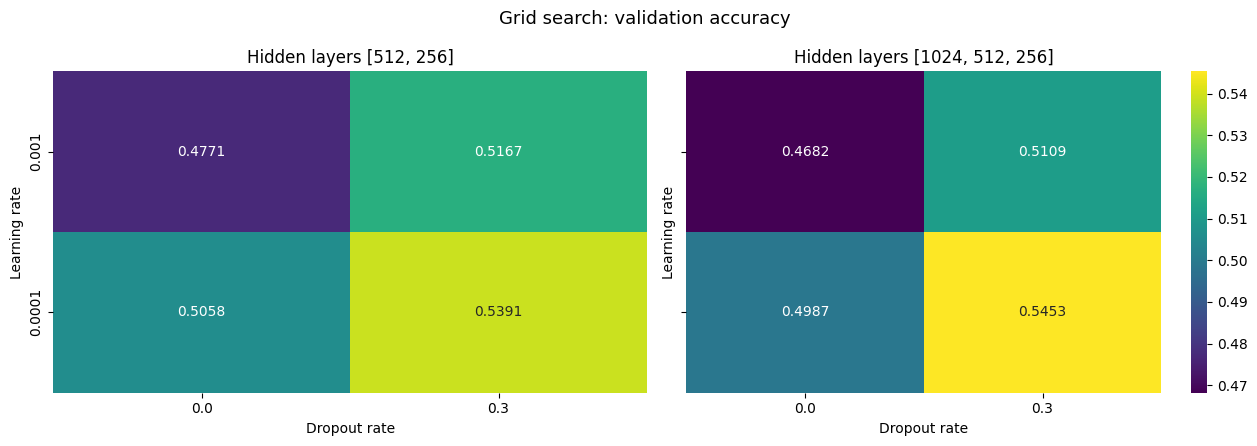

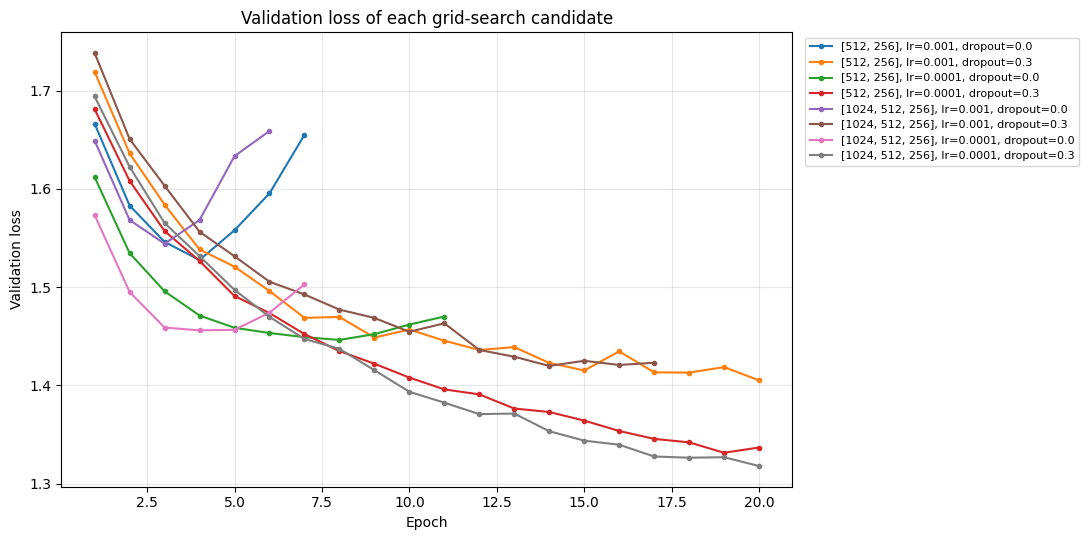

In [8]:
# Visualize the grid: validation accuracy for every combination
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, hu in zip(axes, param_grid['hidden_units']):
    sub = grid_df[grid_df['hidden_units'] == str(list(hu))]
    table = sub.pivot(index='learning_rate', columns='dropout', values='val_acc').sort_index(ascending=False)
    sns.heatmap(table, annot=True, fmt='.4f', cmap='viridis', vmin=grid_df['val_acc'].min(),
                vmax=grid_df['val_acc'].max(), cbar=ax is axes[-1], ax=ax)
    ax.set_title(f'Hidden layers {list(hu)}')
    ax.set_xlabel('Dropout rate')
    ax.set_ylabel('Learning rate')
plt.suptitle('Grid search: validation accuracy', fontsize=13)
plt.tight_layout()
plt.show()

# Validation-loss curves of every candidate
fig, ax = plt.subplots(figsize=(11, 5.5))
for key, h in grid_histories.items():
    ax.plot(np.arange(1, len(h['val_loss']) + 1), h['val_loss'], marker='o', markersize=3,
            label=f'{key[0]}, lr={key[1]:g}, dropout={key[2]}')
ax.set_xlabel('Epoch')
ax.set_ylabel('Validation loss')
ax.set_title('Validation loss of each grid-search candidate')
ax.grid(alpha=0.3)
ax.legend(fontsize=8, loc='upper left', bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

### Training the tuned network

The best combination is retrained from scratch for up to 60 epochs. Early stopping (patience 8) monitors validation loss and restores the weights from the epoch with the lowest validation loss; the curves still show the extra epochs after that point, so the onset of overfitting is visible.

In [9]:
keras.utils.set_random_seed(SEED)
tuned_model = build_mlp(**best_params)
tuned_model.summary()

stop = keras.callbacks.EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True)
history = tuned_model.fit(X_train, y_train, validation_data=(X_val, y_val),
                          epochs=60, batch_size=BATCH_SIZE, callbacks=[stop], verbose=2)
h = history.history
best_epoch = int(np.argmin(h['val_loss'])) + 1
print('Epochs run:', len(h['loss']), '| best epoch (min validation loss):', best_epoch)

Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_28 (Dense)                │ (None, 1024)           │     3,146,752 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_29 (Dense)                │ (None, 512)            │       524,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_11 (Dropout)            │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_30 (Dense)                │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_12 (Dropout)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_31 (Dense)                │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,805,450 (14.52 MB)

 Trainable params: 3,805,450 (14.52 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/60


... (68 outputs left out)

274/274 - 10s - 36ms/step - accuracy: 0.7050 - loss: 0.8220 - val_accuracy: 0.5539 - val_loss: 1.3334


Epoch 36/60


274/274 - 10s - 36ms/step - accuracy: 0.7143 - loss: 0.8085 - val_accuracy: 0.5523 - val_loss: 1.3373


Epochs run: 36 | best epoch (min validation loss): 28


### 1(iii) Training and validation losses of the tuned network

Training loss  : 0.6992
Validation loss: 1.2992


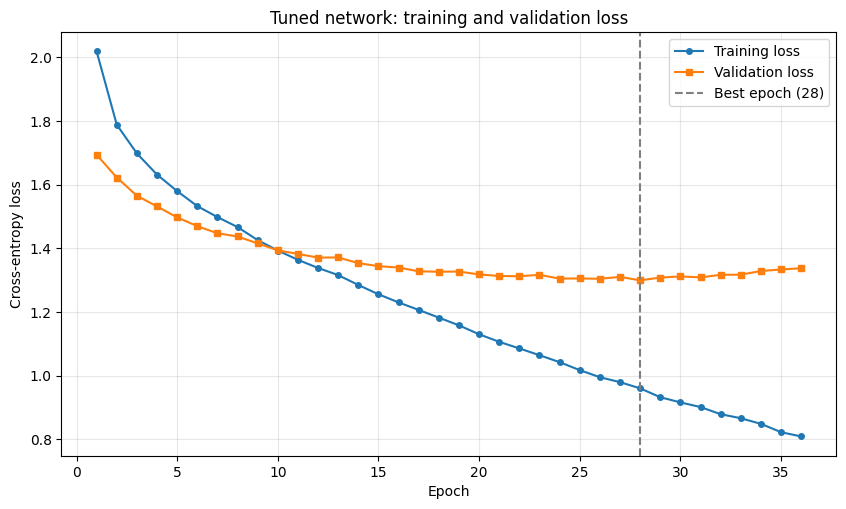

In [10]:
# Final losses of the restored (best) model. evaluate() runs with dropout switched off,
# so this training loss is the true loss on the training data.
train_loss, train_acc = tuned_model.evaluate(X_train, y_train, verbose=0)
val_loss, val_acc = tuned_model.evaluate(X_val, y_val, verbose=0)
print(f'Training loss  : {train_loss:.4f}')
print(f'Validation loss: {val_loss:.4f}')

epochs = np.arange(1, len(h['loss']) + 1)
plt.figure(figsize=(10, 5.5))
plt.plot(epochs, h['loss'], 'o-', markersize=4, label='Training loss')
plt.plot(epochs, h['val_loss'], 's-', markersize=4, label='Validation loss')
plt.axvline(best_epoch, color='gray', linestyle='--', label=f'Best epoch ({best_epoch})')
plt.xlabel('Epoch')
plt.ylabel('Cross-entropy loss')
plt.title('Tuned network: training and validation loss')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### 1(iv) Training and validation accuracies of the tuned network

Training accuracy  : 0.7856
Validation accuracy: 0.5547
Test accuracy (held-out 10,000 images, never used for tuning): 0.5506


Validation accuracy computed manually: 0.5547


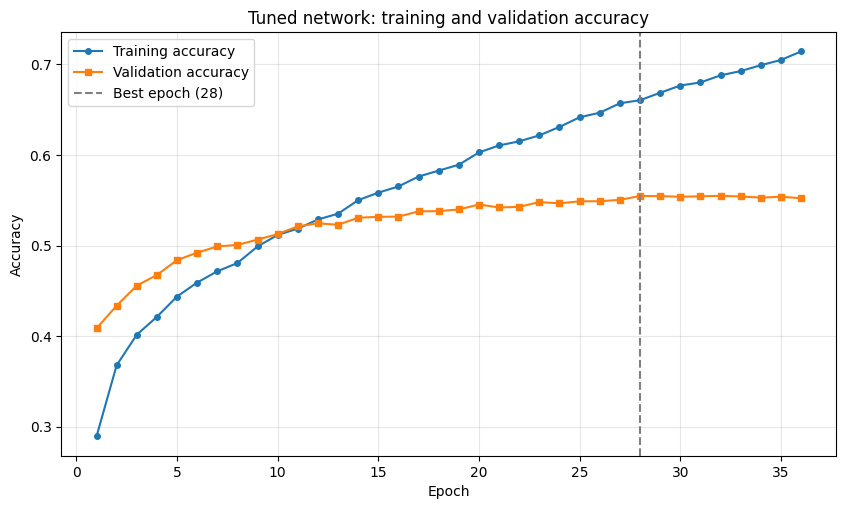

In [11]:
test_loss, test_acc = tuned_model.evaluate(X_test, y_test, verbose=0)
print(f'Training accuracy  : {train_acc:.4f}')
print(f'Validation accuracy: {val_acc:.4f}')
print(f'Test accuracy (held-out 10,000 images, never used for tuning): {test_acc:.4f}')

# Cross-check Keras' accuracy against a direct computation from the predictions
val_pred = tuned_model.predict(X_val, verbose=0).argmax(axis=1)
print(f'Validation accuracy computed manually: {np.mean(val_pred == y_val):.4f}')

plt.figure(figsize=(10, 5.5))
plt.plot(epochs, h['accuracy'], 'o-', markersize=4, label='Training accuracy')
plt.plot(epochs, h['val_accuracy'], 's-', markersize=4, label='Validation accuracy')
plt.axvline(best_epoch, color='gray', linestyle='--', label=f'Best epoch ({best_epoch})')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Tuned network: training and validation accuracy')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

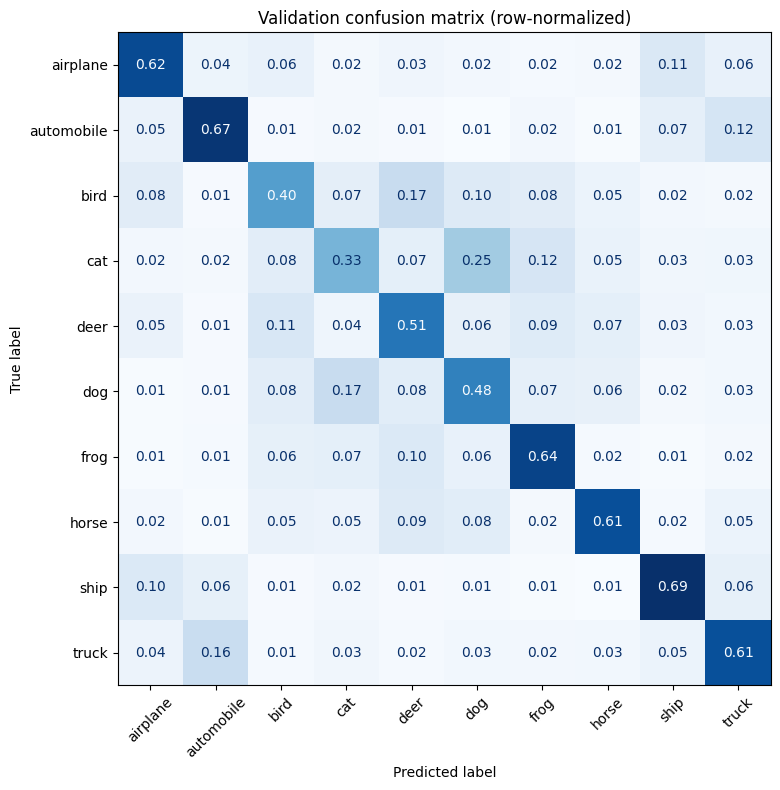

ship          0.691
automobile    0.674
frog          0.639
airplane      0.619
horse         0.609
truck         0.607
deer          0.508
dog           0.477
bird          0.395
cat           0.328
Name: val accuracy, dtype: float64

In [12]:
# Where the tuned network makes mistakes (validation set)
cm = confusion_matrix(y_val, val_pred, normalize='true')
fig, ax = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(ax=ax, cmap='Blues', values_format='.2f',
                                                             xticks_rotation=45, colorbar=False)
ax.set_title('Validation confusion matrix (row-normalized)')
plt.tight_layout()
plt.show()

per_class = pd.Series(np.diag(cm), index=class_names, name='val accuracy').sort_values(ascending=False)
per_class.round(3)

### Problem 1 discussion

- **Grid search.** The best combination is **hidden layers [1024, 512, 256], learning rate 1e-4, dropout 0.3** (validation accuracy 0.545). Dropout was the most important hyperparameter: it improved validation accuracy by 3–5 percentage points in all four (architecture, learning rate) pairs, because without it the network overfits within 3–8 epochs. The lower learning rate (1e-4) was better than 1e-3 in every case. The deeper/wider network helped only slightly when combined with dropout and a small learning rate. The two best candidates were still improving at the 20-epoch limit, so the tuned network is retrained for longer.
- **Loss curves.** Training loss keeps decreasing, but validation loss reaches its minimum at the best epoch and then flattens or rises; the growing gap is overfitting. Early stopping keeps the weights from the best epoch.
- **Accuracy curves.** The tuned network reaches its lowest validation loss at epoch 28, where **training accuracy = 0.786** and **validation accuracy = 0.555** (validation loss 1.299, training loss 0.699, both computed with `evaluate()` on the restored weights). Accuracy on the untouched 10,000-image test set is **0.551**, almost the same as validation accuracy, so the validation estimate is not biased by the tuning. The training curve in the plot is lower than 0.786 because Keras records it during the epoch with dropout active. After about epoch 10, training accuracy keeps rising while validation accuracy levels off near 0.55, which shows the onset of overfitting.
- **Why accuracy is limited.** A fully connected network treats each of the 3072 pixel values as an unrelated input, so it has no notion of spatial locality or translation invariance. Per-class results show it does best on classes with distinctive colors/backgrounds (ship 0.69, automobile 0.67, frog 0.64, airplane 0.62) and worst on visually similar animals (cat 0.33, bird 0.40, dog 0.48, deer 0.51). Convolutional networks typically reach much higher accuracy on CIFAR-10 for this reason.

## Problem 2: Fully connected neural network for the NASA airfoil self-noise dataset

Source: UCI Machine Learning Repository, *Airfoil Self-Noise* (NASA, NACA 0012 airfoils). 1503 samples, 5 inputs, 1 output.

In [13]:
cols = ['Frequency [Hz]', 'Angle of attack [deg]', 'Chord length [m]',
        'Free-stream velocity [m/s]', 'Suction side displacement thickness [m]',
        'Scaled sound pressure level [dB]']
url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/00291/airfoil_self_noise.dat'
path = 'airfoil_self_noise.dat' if os.path.exists('airfoil_self_noise.dat') else url
df = pd.read_csv(path, sep='\t', header=None, names=cols)

features, target = cols[:5], cols[5]
print('Shape:', df.shape, '| missing values:', int(df.isna().sum().sum()))
df.head()

Shape: (1503, 6) | missing values: 0


,Frequency [Hz],Angle of attack [deg],Chord length [m],Free-stream velocity [m/s],Suction side displacement thickness [m],Scaled sound pressure level [dB]
0,800,0.0,0.3048,71.3,0.002663,126.201
1,1000,0.0,0.3048,71.3,0.002663,125.201
2,1250,0.0,0.3048,71.3,0.002663,125.951
3,1600,0.0,0.3048,71.3,0.002663,127.591
4,2000,0.0,0.3048,71.3,0.002663,127.461


In [14]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Frequency [Hz],1503.0,2886.380572,3152.573137,200.000000,800.000000,1600.000000,4000.000000,20000.000000
Angle of attack [deg],1503.0,6.782302,5.918128,0.000000,2.000000,5.400000,9.900000,22.200000
Chord length [m],1503.0,0.136548,0.093541,0.025400,0.050800,0.101600,0.228600,0.304800
Free-stream velocity [m/s],1503.0,50.860745,15.572784,31.700000,39.600000,39.600000,71.300000,71.300000
Suction side displacement thickness [m],1503.0,0.011140,0.013150,0.000401,0.002535,0.004957,0.015576,0.058411
Scaled sound pressure level [dB],1503.0,124.835943,6.898657,103.380000,120.191000,125.721000,129.995500,140.987000


In [15]:
print('Number of distinct values of each attribute:')
df.nunique()

Number of distinct values of each attribute:


Frequency [Hz]                               21
Angle of attack [deg]                        27
Chord length [m]                              6
Free-stream velocity [m/s]                    4
Suction side displacement thickness [m]     105
Scaled sound pressure level [dB]           1456
dtype: int64

### 2(i) Visualizing the dataset

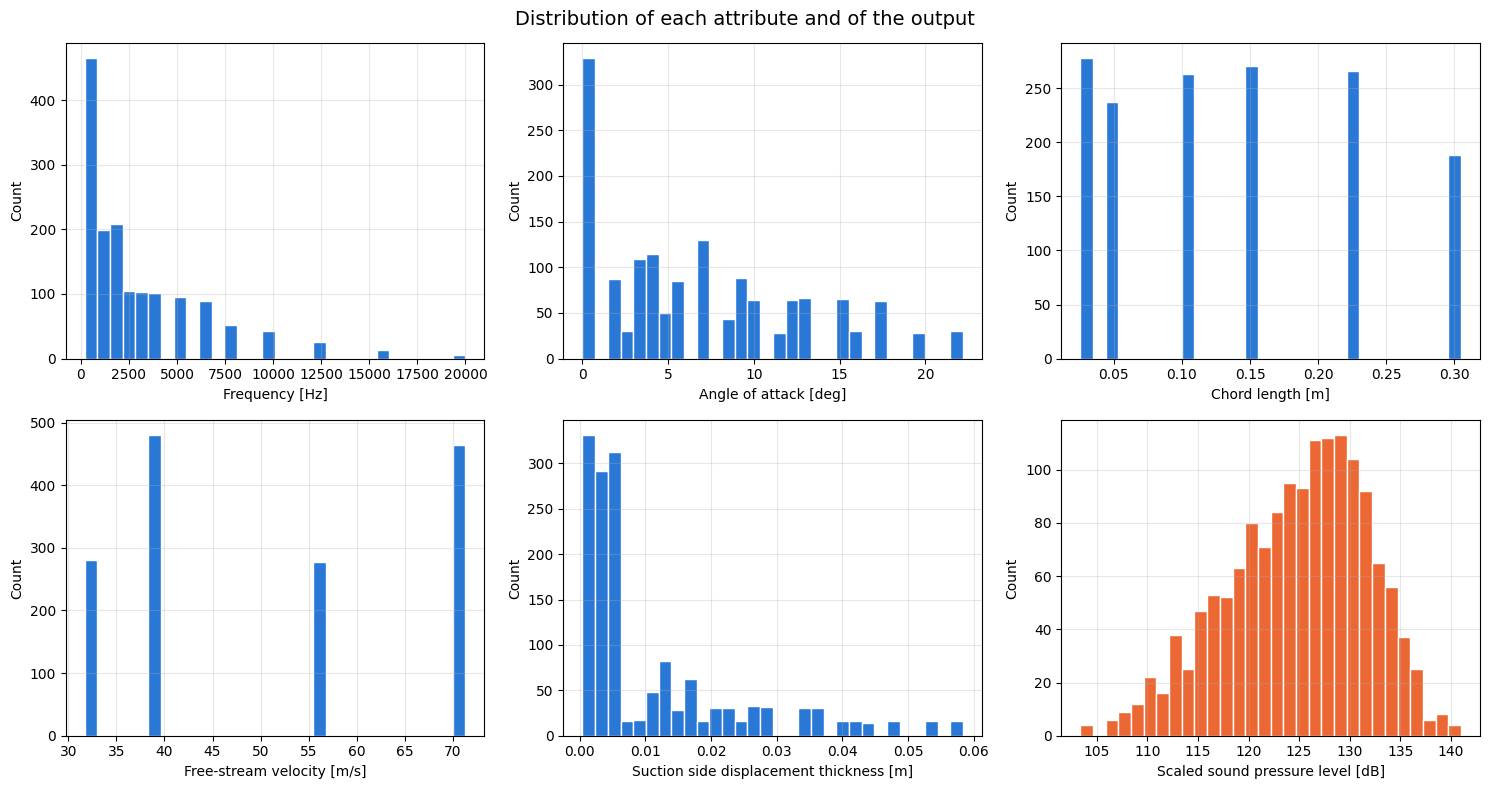

In [16]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, c in zip(axes.flat, cols):
    ax.hist(df[c], bins=30, color='#2a78d6' if c != target else '#eb6834', edgecolor='white')
    ax.set_xlabel(c)
    ax.set_ylabel('Count')
    ax.grid(alpha=0.3)
plt.suptitle('Distribution of each attribute and of the output', fontsize=14)
plt.tight_layout()
plt.show()

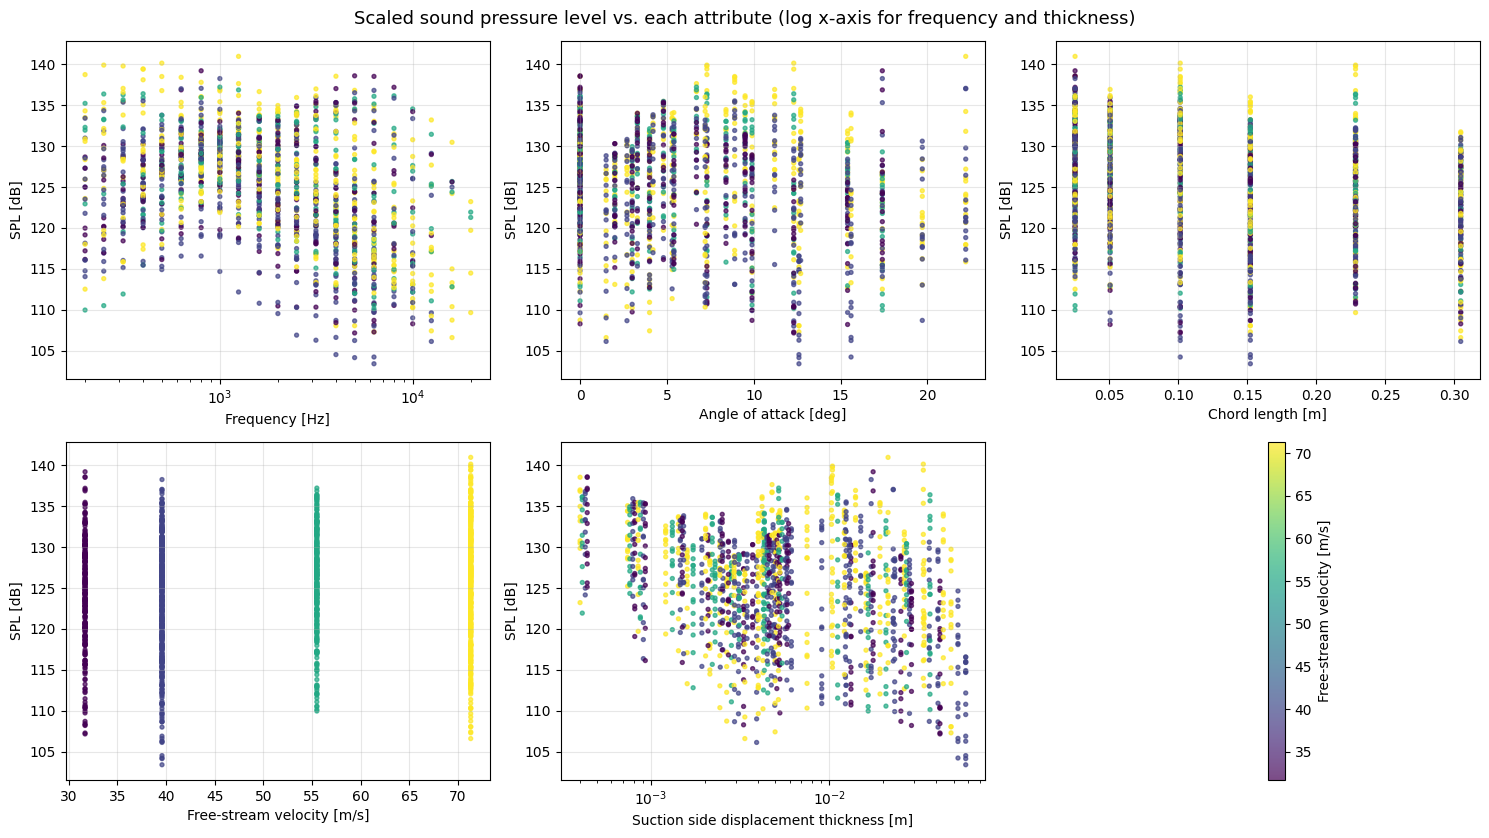

In [17]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8.5))
for ax, c in zip(axes.flat, features):
    sc = ax.scatter(df[c], df[target], c=df['Free-stream velocity [m/s]'], cmap='viridis', s=8, alpha=0.7)
    ax.set_xlabel(c)
    ax.set_ylabel('SPL [dB]')
    ax.grid(alpha=0.3)
    if c in ('Frequency [Hz]', 'Suction side displacement thickness [m]'):
        ax.set_xscale('log')
axes.flat[-1].axis('off')
fig.colorbar(sc, ax=axes.flat[-1], fraction=0.5, label='Free-stream velocity [m/s]')
plt.suptitle('Scaled sound pressure level vs. each attribute (log x-axis for frequency and thickness)', fontsize=13)
plt.tight_layout()
plt.show()

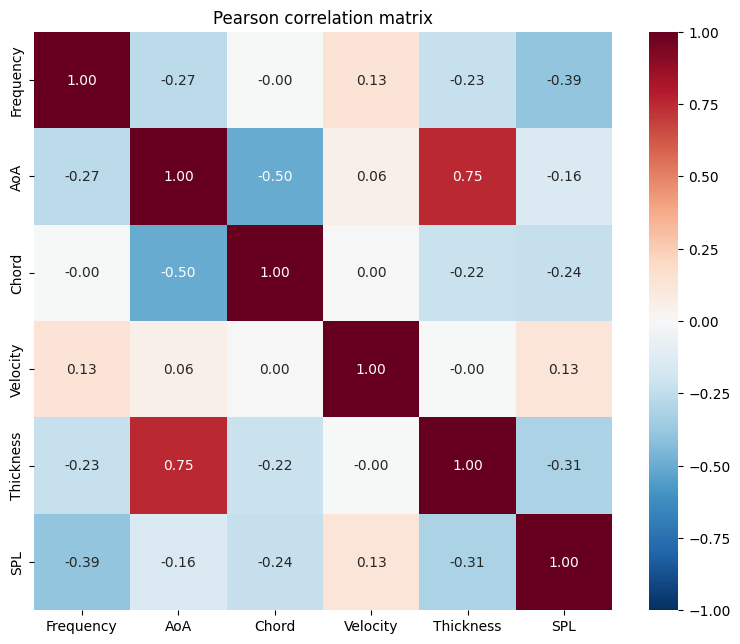

In [18]:
plt.figure(figsize=(8, 6.5))
short = ['Frequency', 'AoA', 'Chord', 'Velocity', 'Thickness', 'SPL']
sns.heatmap(df.set_axis(short, axis=1).corr(), annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, square=True)
plt.title('Pearson correlation matrix')
plt.tight_layout()
plt.show()

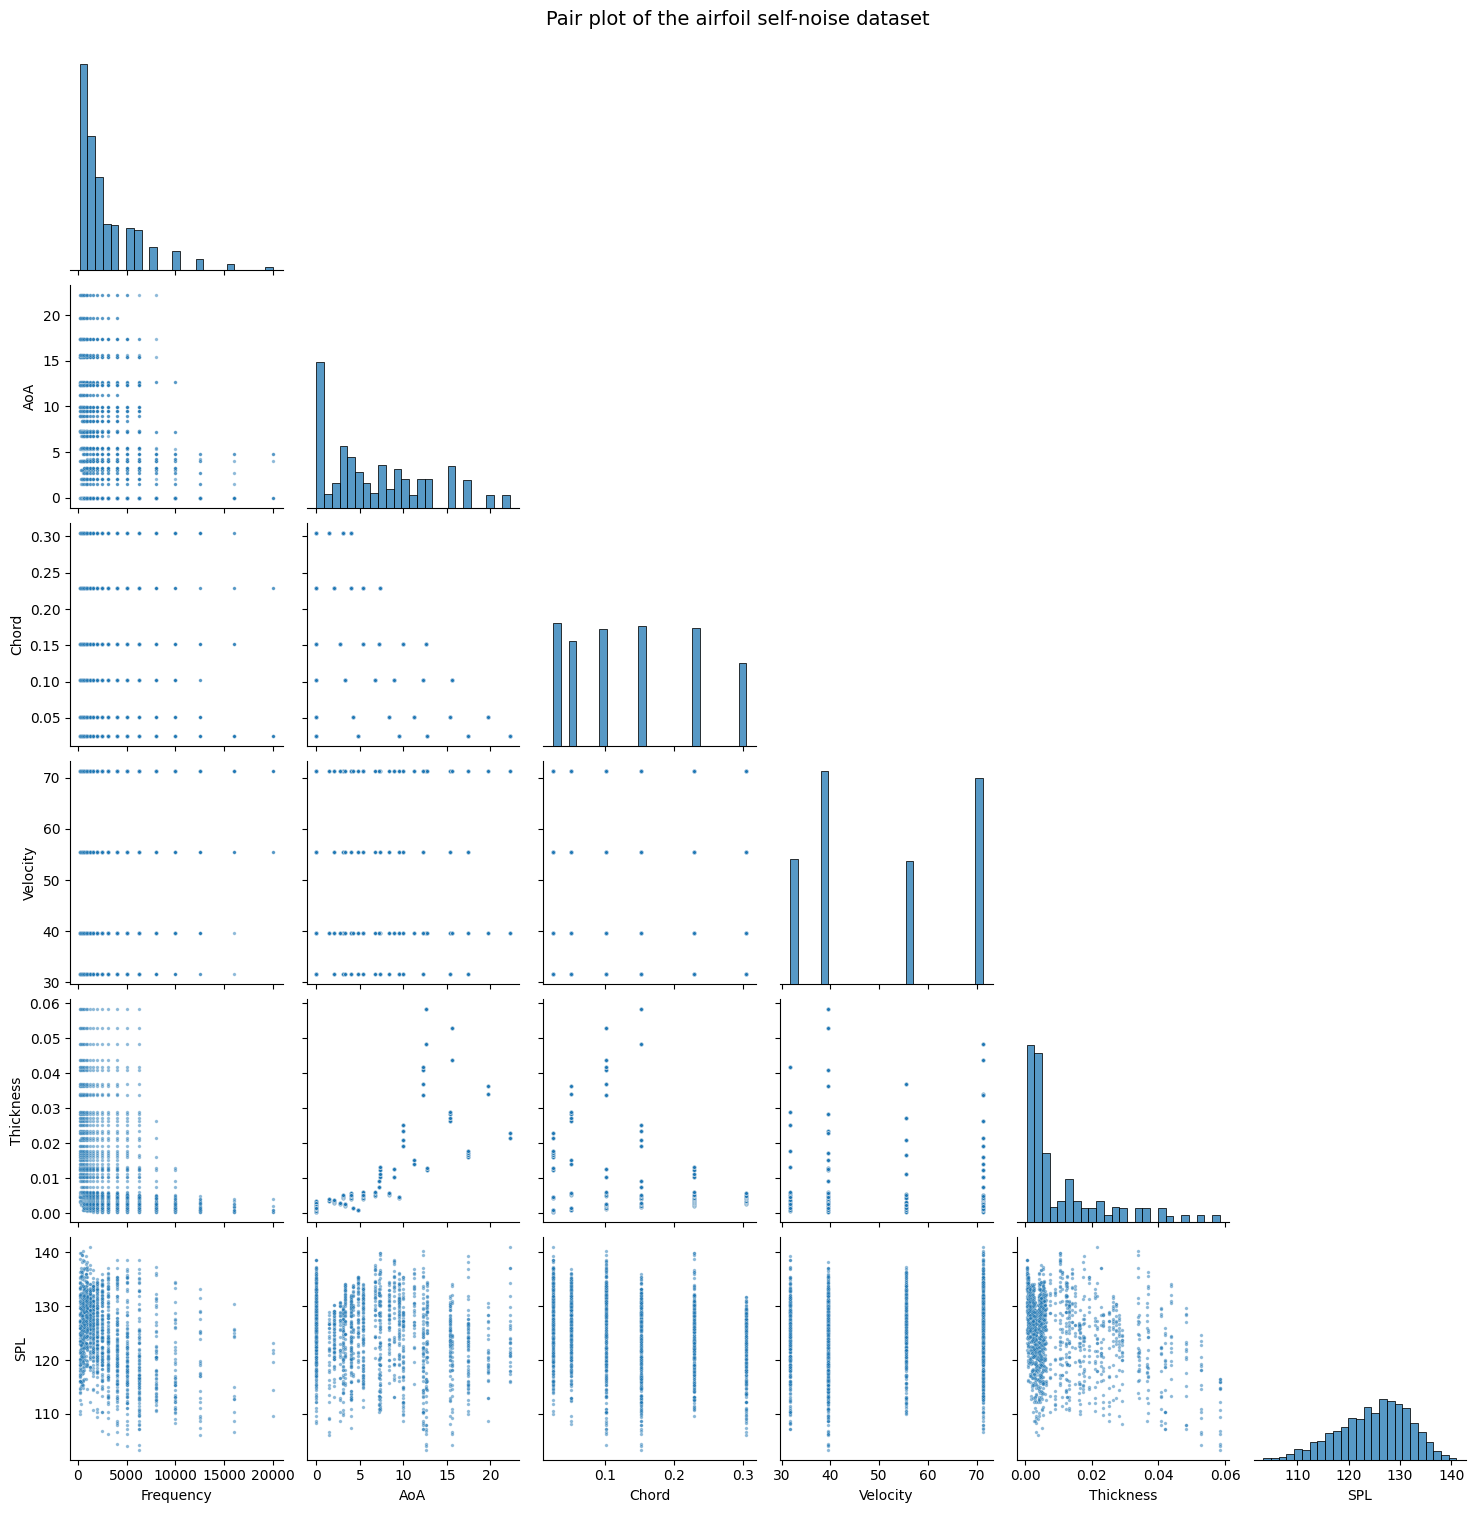

In [19]:
g = sns.pairplot(df.set_axis(short, axis=1), corner=True, plot_kws={'s': 6, 'alpha': 0.5}, diag_kws={'bins': 25})
g.figure.suptitle('Pair plot of the airfoil self-noise dataset', y=1.01, fontsize=14)
plt.show()

**Observations.**
- The inputs take only a few discrete values (6 chord lengths, 4 velocities, 27 angles of attack) because they come from a designed wind-tunnel test matrix. Frequency and displacement thickness are strongly right-skewed and span 2–3 orders of magnitude.
- SPL falls off with frequency (correlation ≈ −0.39), and decreases with displacement thickness and chord length. No single input explains SPL well; the relationship is nonlinear and involves interactions, which is a good use case for a neural network.
- Because frequency and thickness are log-distributed, they are log₁₀-transformed before standardization. This spreads the samples evenly across the input range and makes the network easier to train.

### 2(ii) Fully connected neural network (70% / 30% split)

- Split: 70% training (1052 samples), 30% test (451 samples), `random_state=42`.
- Inputs: log₁₀ of frequency and thickness; then every input is standardized with the training-set mean and standard deviation. The output is also standardized for training (and converted back to dB for evaluation).
- Network: 5 → 128 (ReLU) → 128 (ReLU) → 64 (ReLU) → 1 (linear). Loss: mean squared error. Optimizer: Adam (learning rate 1e-3), batch size 32, 500 epochs.
- The 30% set is passed to `fit` only so its loss can be plotted; it is never used to update the weights or to stop training.

In [20]:
X = df[features].values.copy()
y = df[target].values
X[:, 0] = np.log10(X[:, 0])   # frequency
X[:, 4] = np.log10(X[:, 4])   # displacement thickness

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.30, random_state=SEED)
print('Training:', X_tr.shape, ' Test:', X_te.shape,
      ' fraction %.2f / %.2f' % (len(X_tr) / len(X), len(X_te) / len(X)))

x_scaler = StandardScaler().fit(X_tr)
X_tr_s, X_te_s = x_scaler.transform(X_tr), x_scaler.transform(X_te)
y_mean, y_std = y_tr.mean(), y_tr.std()
y_tr_s, y_te_s = (y_tr - y_mean) / y_std, (y_te - y_mean) / y_std

Training: (1052, 5)  Test: (451, 5)  fraction 0.70 / 0.30


In [21]:
keras.utils.set_random_seed(SEED)
reg_model = keras.Sequential([
    keras.Input(shape=(5,)),
    layers.Dense(128, activation='relu'),
    layers.Dense(128, activation='relu'),
    layers.Dense(64, activation='relu'),
    layers.Dense(1),
])
reg_model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3), loss='mse')
reg_model.summary()

reg_hist = reg_model.fit(X_tr_s, y_tr_s, validation_data=(X_te_s, y_te_s),
                         epochs=500, batch_size=32, verbose=0)
print('Final training MSE (standardized units): %.4f' % reg_hist.history['loss'][-1])
print('Final test MSE (standardized units)    : %.4f' % reg_hist.history['val_loss'][-1])

Model: "sequential_9"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_32 (Dense)                │ (None, 128)            │           768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_33 (Dense)                │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_34 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_35 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 25,601 (100.00 KB)

 Trainable params: 25,601 (100.00 KB)

 Non-trainable params: 0 (0.00 B)

Final training MSE (standardized units): 0.0039
Final test MSE (standardized units)    : 0.0320


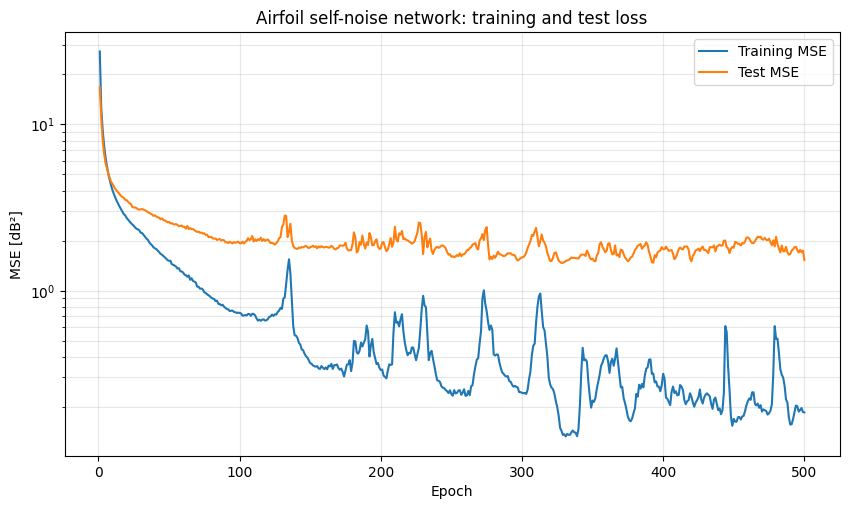

In [22]:
# Convert standardized MSE to dB^2 (MSE scales with y_std^2)
plt.figure(figsize=(10, 5.5))
ep = np.arange(1, len(reg_hist.history['loss']) + 1)
plt.plot(ep, np.array(reg_hist.history['loss']) * y_std**2, label='Training MSE')
plt.plot(ep, np.array(reg_hist.history['val_loss']) * y_std**2, label='Test MSE')
plt.yscale('log')
plt.xlabel('Epoch')
plt.ylabel('MSE [dB²]')
plt.title('Airfoil self-noise network: training and test loss')
plt.legend()
plt.grid(alpha=0.3, which='both')
plt.show()

### 2(iii) Coefficient of determination

$$R^2 = 1 - \frac{\sum_i (y_i - \hat y_i)^2}{\sum_i (y_i - \bar y)^2}$$

In [23]:
yhat_tr = reg_model.predict(X_tr_s, verbose=0).ravel() * y_std + y_mean
yhat_te = reg_model.predict(X_te_s, verbose=0).ravel() * y_std + y_mean

def r2_manual(y_true, y_pred):
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - y_true.mean()) ** 2)
    return 1 - ss_res / ss_tot

r2_tr, r2_te = r2_score(y_tr, yhat_tr), r2_score(y_te, yhat_te)
rmse_tr = np.sqrt(np.mean((y_tr - yhat_tr) ** 2))
rmse_te = np.sqrt(np.mean((y_te - yhat_te) ** 2))
print(f'Training set (70%): R^2 = {r2_tr:.4f}  (manual {r2_manual(y_tr, yhat_tr):.4f}),  RMSE = {rmse_tr:.3f} dB')
print(f'Test set     (30%): R^2 = {r2_te:.4f}  (manual {r2_manual(y_te, yhat_te):.4f}),  RMSE = {rmse_te:.3f} dB')

Training set (70%): R^2 = 0.9896  (manual 0.9896),  RMSE = 0.704 dB
Test set     (30%): R^2 = 0.9676  (manual 0.9676),  RMSE = 1.236 dB


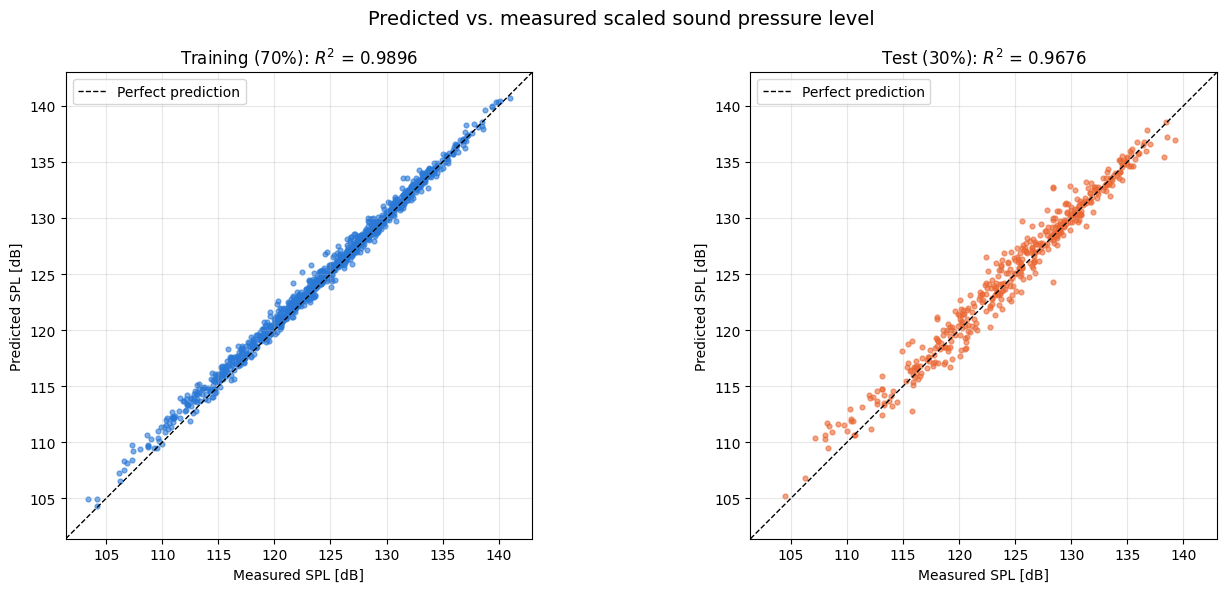

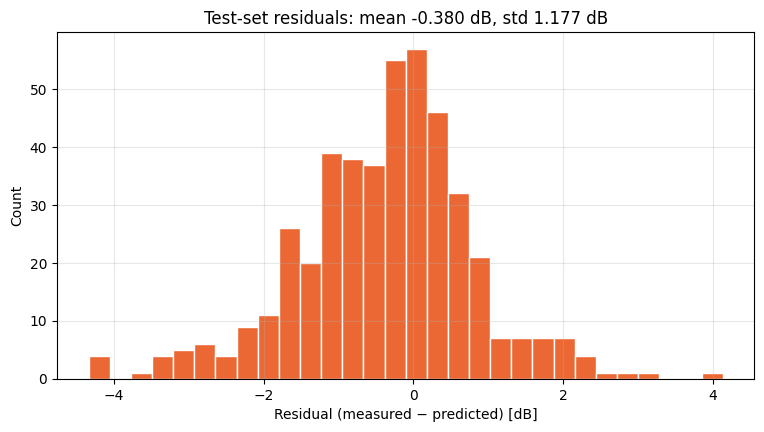

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
lims = [min(y.min(), yhat_te.min(), yhat_tr.min()) - 2, max(y.max(), yhat_te.max(), yhat_tr.max()) + 2]
for ax, yt, yp, name, r2, c in [(axes[0], y_tr, yhat_tr, 'Training (70%)', r2_tr, '#2a78d6'),
                                (axes[1], y_te, yhat_te, 'Test (30%)', r2_te, '#eb6834')]:
    ax.scatter(yt, yp, s=12, alpha=0.6, color=c)
    ax.plot(lims, lims, 'k--', linewidth=1, label='Perfect prediction')
    ax.set_xlim(lims); ax.set_ylim(lims)
    ax.set_xlabel('Measured SPL [dB]')
    ax.set_ylabel('Predicted SPL [dB]')
    ax.set_title(f'{name}: $R^2$ = {r2:.4f}')
    ax.set_aspect('equal')
    ax.legend()
    ax.grid(alpha=0.3)
plt.suptitle('Predicted vs. measured scaled sound pressure level', fontsize=14)
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 4.5))
plt.hist(y_te - yhat_te, bins=30, color='#eb6834', edgecolor='white')
plt.xlabel('Residual (measured − predicted) [dB]')
plt.ylabel('Count')
plt.title(f'Test-set residuals: mean {np.mean(y_te - yhat_te):.3f} dB, std {np.std(y_te - yhat_te):.3f} dB')
plt.grid(alpha=0.3)
plt.show()

In [25]:
# Baseline for context: ordinary linear regression on the same split and features
from sklearn.linear_model import LinearRegression
lin = LinearRegression().fit(X_tr_s, y_tr)
print(f'Linear regression test R^2: {r2_score(y_te, lin.predict(X_te_s)):.4f}')
print(f'Neural network    test R^2: {r2_te:.4f}')

Linear regression test R^2: 0.4234
Neural network    test R^2: 0.9676


### Problem 2 discussion

- **Coefficient of determination:** $R^2$ = **0.968 on the 30% test set** (0.990 on the 70% training set). The sklearn `r2_score` and the manual formula give identical values.
- **RMSE:** 1.24 dB (test) and 0.70 dB (training), compared with an SPL standard deviation of 6.9 dB. Test residuals are centered near zero.
- The network explains about 97% of the variance in sound pressure level on data it never saw. A linear regression on the same inputs reaches only $R^2$ = 0.42, so most of the explained variance comes from nonlinear effects and interactions between frequency, velocity, chord, angle of attack and boundary-layer thickness.
- The gap between training (0.990) and test (0.968) $R^2$, and the loss plot (test MSE levels off near 1.5–2 dB² after about 150 epochs while training MSE keeps falling), show mild overfitting. With only 1052 training samples, adding regularization or early stopping on a separate validation set could narrow it slightly.